# 06 · Model B: noise-augmented training on 100 h
**Project:** Noise-Robust Speech Recognition with Word-Level Error Detection (Group 9) · Milestone 4

**Why we trained it.** Objective **O2**: does training on noisy audio make the model robust to *unseen* noise? Model B uses **exactly
Model A's recipe, data and seed**; the only change is on-the-fly noise: 80 % of training utterances get white, pink
or MUSAN (training files only) noise mixed in at a random SNR of 0–20 dB. Any difference between A and B is therefore
caused by the noise training. Brown noise and ESC-50 are never used in training: they are the held-out test noises.

**Recipe.** As A, plus noise augmentation (p_clean 0.2, SNR uniform 0–20 dB).

| | |
|---|---|
| Run name | `B_noisy` |
| Config | `configs/train_B_noisy.yaml` (saved copy with all defaults: `experiments/runs/B_noisy/config.json`) |
| Training / validation logs | `experiments/runs/B_noisy/train_log.csv`, `eval_log.csv` |
| Test results | `experiments/results/B_noisy/` (greedy), `B_noisy_lm4/` (4-gram LM), `B_noisy_ext/` (reverb, −5 dB) |
| Trained model | [wav2vec2-base-ls100-noise-aug](https://huggingface.co/kumargulshan/wav2vec2-base-ls100-noise-aug) on Hugging Face (also `experiments/runs/B_noisy/best/` on the server) |
| Compared with | A_clean |

All tables and figures are computed from small files that are in the repository, so the notebook runs on a fresh
clone without the data or a GPU. Only the last section (live transcription) needs the model weights, which it
loads from the server folder or, if `DOWNLOAD = True`, from Hugging Face. All models are compared side by side in
notebook `M4_11_all_models_comparison.ipynb`.

**Contents:** 1 Setup · 2 Configuration · 3 Training · 4 Validation and checkpoint selection · 5 Test results
(greedy) · 6 Test results with the 4-gram LM · 7 Harder held-out conditions · 8 Word-level error detection ·
9 Comparison with A_clean · 10 Live transcription example · 11 Summary

## 1 · Setup

In [1]:
import sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import *   # noqa  (RUNS, EVAL, CONFIGS, ...)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from group9_ds_ai_lab.utils.plotstyle import apply_style, SERIES, INK, INK2, GRID, SURF, NOISE_COLOR
apply_style(); plt.rcParams["axes.axisbelow"] = True; warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 80)

MODEL = "B_noisy"
PARENT = 'A_clean'   # model this one is compared with
HF_ID = "kumargulshan/wav2vec2-base-ls100-noise-aug"
COLOR = {MODEL: SERIES[1], PARENT: "#9a9893"}
N_WORDS = {"test.clean": 52576, "test.other": 52343}   # reference words per test split (for exact pooling)
print("repo:", REPO, "| model:", MODEL, "| compared with:", PARENT)

repo: /home/user1/DSAI/Group-9-DS-and-AI-Lab-Project | model: B_noisy | compared with: A_clean


## 2 · Configuration
The YAML file is what we wrote (with our comments); `config.json` is what `scripts/train.py` actually used, after
merging the YAML with the defaults in `configs/training.yaml`.

In [2]:
print((CONFIGS / f"train_{MODEL}.yaml").read_text())
cfg = json.load(open(RUNS / MODEL / "config.json"))
display(pd.Series({k: str(v) for k, v in cfg.items()}, name="value").to_frame())

# Model B: identical recipe, + on-the-fly noise (white, pink, MUSAN noise/music; 20% clean; SNR ~ U[0,20] dB)
name: B_noisy
init_model: facebook/wav2vec2-base
augment: true
p_clean: 0.2
snr_min: 0.0
snr_max: 20.0
max_steps: 36000          # ~64 epochs of 100 h at 640 s/step (smoke test: ~1.9k audio-s/s alone)
lr: 5.0e-5
warmup_ratio: 0.08
max_batch_seconds: 640    # padded audio seconds per optimizer step
eval_every: 2000
save_every: 2000
seed: 42
# regularisation (close to the fairseq wav2vec2 base 100h recipe, slightly milder)
mask_time_prob: 0.4
mask_time_length: 10
mask_feature_prob: 0.1
mask_feature_length: 64
layerdrop: 0.1
num_workers: 28



,value
name,B_noisy
init_model,facebook/wav2vec2-base
augment,True
p_clean,0.2
snr_min,0.0
snr_max,20.0
max_steps,36000
lr,5e-05
warmup_ratio,0.08
weight_decay,0.005


## 3 · Training
`train_log.csv` has one row every 50 optimizer steps. The gradient norm is logged **before** clipping to 1.0.

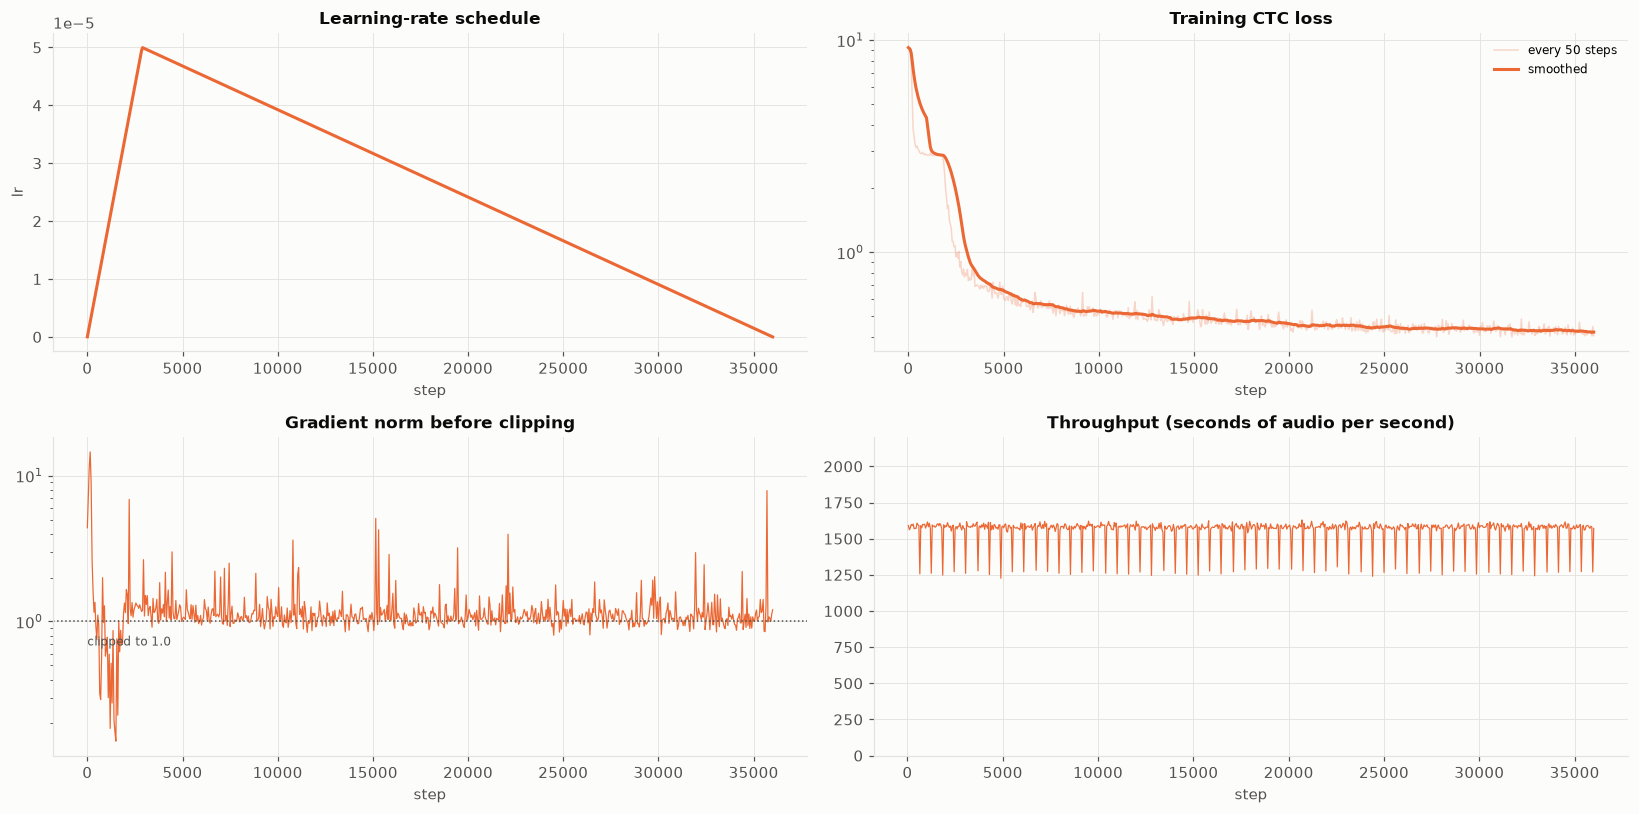

,value
optimizer steps,36000
epochs,59
GPU hours (1 × L40S),3.83
median s / step,0.377
audio seconds per second,1581
peak GPU memory (GB),10.85
max gradient norm (before clipping),14.55
steps with gradient norm > 1 (clipped),74 % of logged steps
non-finite losses,0
"training loss, first 1k steps → last 1k steps",4.243 → 0.421


In [3]:
tl = pd.read_csv(RUNS / MODEL / "train_log.csv"); el = pd.read_csv(RUNS / MODEL / "eval_log.csv")
c = COLOR[MODEL]
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5))
axes[0, 0].plot(tl.step, tl.lr, color=c); axes[0, 0].set(title="Learning-rate schedule", xlabel="step", ylabel="lr")
axes[0, 1].plot(tl.step, tl.loss, color=c, alpha=.25, lw=1, label="every 50 steps")
axes[0, 1].plot(tl.step, tl.loss.rolling(20, min_periods=1).mean(), color=c, label="smoothed")
axes[0, 1].set(title="Training CTC loss", xlabel="step", yscale="log"); axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(tl.step, tl.grad_norm, color=c, lw=.8); axes[1, 0].axhline(1.0, color=INK2, ls=":", lw=1)
axes[1, 0].text(0, .8, "clipped to 1.0", ha="left", va="top", fontsize=8, color=INK2)
axes[1, 0].set(title="Gradient norm before clipping", xlabel="step", yscale="log")
axes[1, 1].plot(tl.step.iloc[1:], tl.audio_sec_per_sec.iloc[1:], color=c, lw=.8)
axes[1, 1].set(title="Throughput (seconds of audio per second)", xlabel="step", ylim=(0, 2200))
plt.tight_layout(); plt.show()

r = tl.iloc[1:]
stats = {"optimizer steps": int(tl.step.max()), "epochs": int(tl.epoch.max()),
         "GPU hours (1 × L40S)": round((r.sec_per_step * tl.step.diff().iloc[1:]).sum() / 3600, 2),
         "median s / step": round(r.sec_per_step.median(), 3), "audio seconds per second": round(r.audio_sec_per_sec.median()),
         "peak GPU memory (GB)": round(tl.max_mem_gb.max(), 2), "max gradient norm (before clipping)": round(tl.grad_norm.max(), 2),
         "steps with gradient norm > 1 (clipped)": f"{100 * (tl.grad_norm > 1).mean():.0f} % of logged steps",
         "non-finite losses": int((~np.isfinite(tl.loss)).sum()),
         "training loss, first 1k steps → last 1k steps": f"{tl[tl.step <= 1000].loss.mean():.3f} → {tl[tl.step > tl.step.max() - 1000].loss.mean():.3f}"}
display(pd.Series(stats, name="value").to_frame())

## 4 · Validation and checkpoint selection
Every 2,000 (B460: 4,000) steps the model is decoded (greedy) on the fixed dev set: 2,000 clean utterances and
2,000 noisy ones (dev speakers, **held-out MUSAN noise files**, 0–20 dB). The checkpoint with the lowest **mean**
of the two WERs is saved as `best/`; that is the model published and evaluated below.

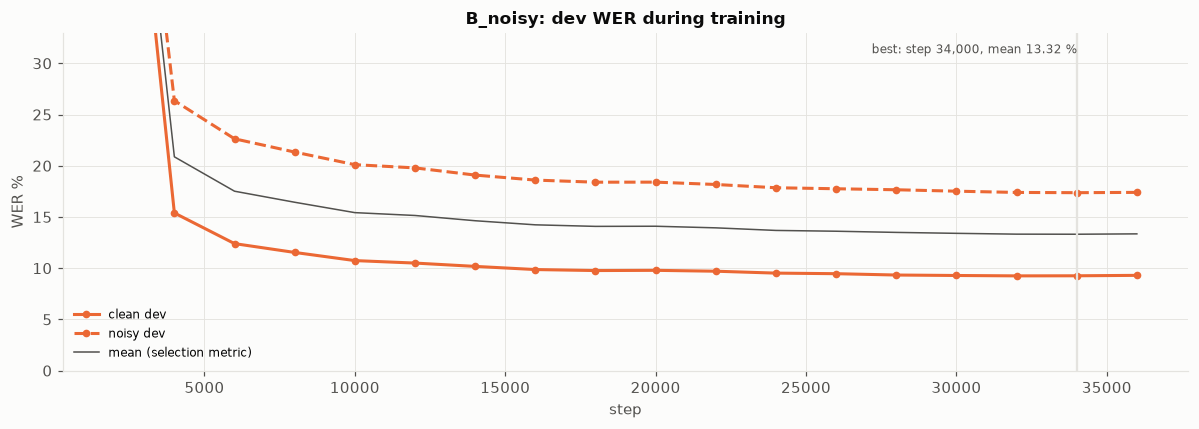

,wer_clean %,wer_noisy %,wer_avg %,cer_clean %,cer_noisy %,empty_hyp_frac %
step,,,,,,
2000,71.60,76.51,74.05,31.23,37.06,0.1
4000,15.39,26.36,20.87,4.86,10.72,0.0
6000,12.40,22.63,17.52,4.00,9.37,0.0
8000,11.54,21.34,16.44,3.83,8.97,0.0
10000,10.74,20.11,15.42,3.60,8.46,0.0
12000,10.50,19.79,15.15,3.56,8.35,0.0
14000,10.18,19.09,14.63,3.45,8.10,0.0
16000,9.87,18.60,14.23,3.38,7.88,0.0
18000,9.77,18.40,14.08,3.37,7.84,0.0


In [4]:
best = el.loc[el.wer_avg.idxmin()]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(el.step, el.wer_clean * 100, color=c, marker="o", ms=4, label="clean dev")
ax.plot(el.step, el.wer_noisy * 100, color=c, marker="o", ms=4, ls="--", label="noisy dev")
ax.plot(el.step, el.wer_avg * 100, color=INK2, lw=1, label="mean (selection metric)")
ax.axvline(best.step, color=GRID, lw=1.5)
ax.annotate(f"best: step {int(best.step):,}, mean {best.wer_avg*100:.2f} %", (best.step, .97), xycoords=("data", "axes fraction"),
            ha="right", va="top", fontsize=8, color=INK2)
top = el.wer_noisy.iloc[1:].max() * 100 * 1.25 if len(el) > 1 else 100
ax.set(title=f"{MODEL}: dev WER during training", xlabel="step", ylabel="WER %", ylim=(0, min(top, 100))); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
t = el[["step", "wer_clean", "wer_noisy", "wer_avg", "cer_clean", "cer_noisy", "empty_hyp_frac"]].copy()
t[t.columns[1:]] = t[t.columns[1:]] * 100
display(t.set_index("step").round(2).rename(columns=lambda s: s + " %"))

How the transcript of one fixed dev utterance changed during training:

In [5]:
ex = el[["step", "example_hyp"]].copy()
print("REFERENCE:", el.example_ref.iloc[0].strip())
with pd.option_context("display.max_colwidth", 120): display(ex.iloc[np.unique(np.linspace(0, len(ex) - 1, 8).astype(int))].set_index("step"))

REFERENCE: HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED


,example_hyp
step,
2000,HAT TO CLS TO M I CODNT GT IT CPLND THONCTHE BS RRED
6000,HAT TO CLOSE TO BME I COULDN'T GET IT EXPLAINED CUNKY THE BOY'S RARED
10000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CUNKY THE BOY'S RARED
16000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CUNKEY THE BOY'S RARED
20000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CUNKEY THE BOY'S RARED
26000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED TUNKEY THE BOY'S RARED
30000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED TUNKEY THE BOY'S RARED
36000,HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CUNKEY THE BOY'S RARED


## 5 · Test results, greedy decoding (no language model)
Test grid: **test-clean** (2,620 utterances) and **test-other** (2,939, harder speakers) × 17 conditions: clean; white,
pink, brown and ESC-50 noise at 20 / 10 / 5 / 0 dB. Test speakers are never seen in training. **Brown noise and ESC-50
were never used in training** (held-out noise types); white and pink are seen *types* but fresh random samples.

In [6]:
def load(path, name=None):
    s = pd.read_csv(path); s["snr_db"] = s.snr_db.astype(str)
    return s.assign(model=name) if name else s

def pool(s):
    # word-weighted pooling of test-clean + test-other (identical to jiwer on all utterances)
    s = s[s.ls_split.isin(N_WORDS)].copy(); s["w"] = s.ls_split.map(N_WORDS)
    return (s.assign(e=s.wer * s.w, ec=s.cer * s.w).groupby(["model", "noise_type", "snr_db"])[["e", "ec", "w"]].sum()
              .pipe(lambda d: pd.DataFrame({"wer": d.e / d.w, "cer": d.ec / d.w})).reset_index())

SNR = ["clean", "20", "10", "5", "0"]; NOISES = ["esc50", "brown", "white", "pink"]
def grid(s, value="wer"):
    s = s.copy(); s.loc[s.noise_type == "clean", "snr_db"] = "clean"
    g = s.pivot_table(index=["ls_split", "noise_type"], columns="snr_db", values=value) * 100
    return g[[c for c in SNR if c in g.columns]].round(2).astype(object).where(g.notna(), "")

G = load(EVAL / MODEL / "summary.csv", MODEL)
display(Markdown("**WER % per split, noise type and SNR (greedy)**")); display(grid(G))
display(Markdown("**CER % (character error rate)**")); display(grid(G, "cer"))

**WER % per split, noise type and SNR (greedy)**

snr_db                 clean     20     10      5      0
ls_split   noise_type                                   
test.clean brown               6.24   6.22    6.3   6.37
           clean        6.19                            
           esc50               6.43   7.69   9.54  15.67
           pink                6.37   7.49  10.04  18.06
           white               6.68   8.74  13.02  23.45
test.other brown              13.13  13.23  13.43  14.02
           clean       13.08                            
           esc50              14.17  17.98  23.01  32.33
           pink               14.04  18.35  25.09   39.7
           white              15.33   22.6  31.51  48.48

**CER % (character error rate)**

snr_db                clean    20    10      5      0
ls_split   noise_type                                
test.clean brown              1.8   1.8   1.84   1.86
           clean       1.78                          
           esc50              1.9  2.44   3.29   6.52
           pink              1.89  2.36   3.48   7.45
           white              2.0   2.9   4.84  10.39
test.other brown             4.71  4.77   4.88   5.09
           clean       4.67                          
           esc50             5.23  7.26   9.99  15.79
           pink              5.15  7.39  11.04  19.84
           white             5.85  9.62  14.91  25.57

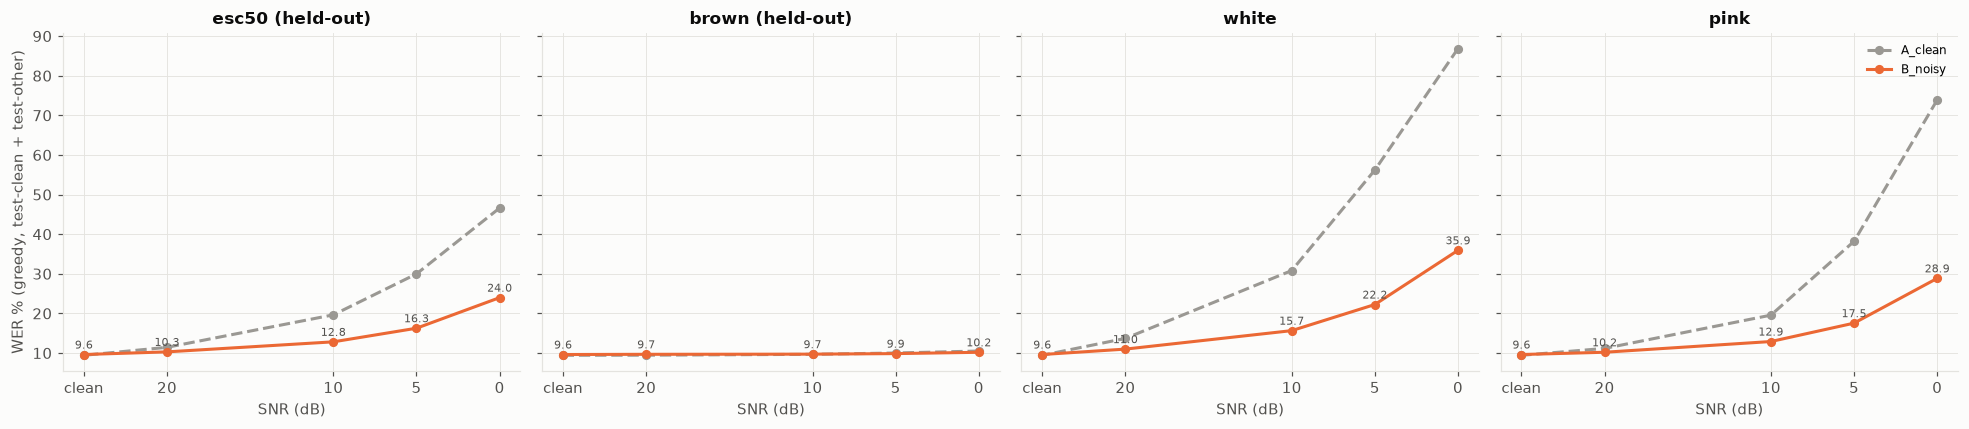

In [7]:
gp = pool(G); X = {"clean": 25, "20": 20, "10": 10, "5": 5, "0": 0}
P = pool(load(EVAL / PARENT / "summary.csv", PARENT))
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, nt in zip(axes, NOISES):
    for name, d, ls in [(PARENT, P, "--"), (MODEL, gp, "-")]:
        q = d[d.noise_type.isin([nt, "clean"])].copy(); q["x"] = q.snr_db.map(X); q = q.sort_values("x")
        ax.plot(q.x, q.wer * 100, marker="o", ms=5, ls=ls, color=COLOR[name], label=name)
        if name == MODEL:
            for x, y in zip(q.x, q.wer * 100):
                ax.text(x, y + 1.5, f"{y:.1f}", ha="center", fontsize=7, color=INK2)
    ax.set_xticks(list(X.values()), SNR); ax.invert_xaxis()
    ax.set(title=nt + (" (held-out)" if nt in ("esc50", "brown") else ""), xlabel="SNR (dB)")
axes[0].set(ylabel="WER % (greedy, test-clean + test-other)"); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6 · Test results with the 4-gram language model
Beam search (pyctcdecode + KenLM) with the official LibriSpeech 4-gram LM: α 0.8, β 2.0, beam 50 (α and β were tuned
on the dev set, once, for Model B, and reused for every model).

In [8]:
L = load(EVAL / f"{MODEL}_lm4" / "test_summary.csv", MODEL)
display(Markdown("**WER % with the 4-gram LM**")); display(grid(L))
lp = pool(L)
def head(p):
    out = {}
    for nt in NOISES:
        out[f"{nt} 0–5 dB"] = p[(p.noise_type == nt) & p.snr_db.isin(["0", "5"])].wer.mean() * 100
    out["all noisy, mean"] = p[p.noise_type != "clean"].wer.mean() * 100
    return out
def split_clean(s, sp): return s[(s.ls_split == sp) & (s.noise_type == "clean")].wer.iloc[0] * 100
H = pd.DataFrame({"greedy": {"test-clean": split_clean(G, "test.clean"), "test-other": split_clean(G, "test.other"), **head(gp)},
                  "4-gram LM": {"test-clean": split_clean(L, "test.clean"), "test-other": split_clean(L, "test.other"), **head(lp)}})
H["LM gain (points)"] = H["greedy"] - H["4-gram LM"]; H["relative %"] = 100 * H["LM gain (points)"] / H["greedy"]
display(H.round(2))
dm = EVAL / f"{MODEL}_lm4" / "dev_metrics.json"
if dm.exists():
    d = json.load(open(dm))
    display(Markdown(f"Dev set with the LM: clean pooled **{d['wer_clean_pooled']*100:.2f} %**, noisy pooled **{d['wer_noisy_pooled']*100:.2f} %**."))
grid_f = EVAL / f"{MODEL}_lm4" / "lm_grid_dev.csv"
if grid_f.exists():
    g = pd.read_csv(grid_f); display(Markdown("**α / β grid on dev (mean of clean and noisy dev WER %)**"))
    display((g.pivot_table(index="alpha", columns="beta", values="wer_avg") * 100).round(2))

**WER % with the 4-gram LM**

snr_db                clean     20     10      5      0
ls_split   noise_type                                  
test.clean brown               3.7   3.69    3.7   3.76
           clean        3.7                            
           esc50               3.9   4.59   6.03  11.06
           pink               3.81   4.56   6.27  12.57
           white              3.98   5.36    8.4   17.1
test.other brown              8.96   9.03   9.17   9.59
           clean       8.85                            
           esc50              9.58  12.85  17.17  26.17
           pink               9.55  13.01  18.88  32.88
           white             10.48  16.54  24.59  41.16

,greedy,4-gram LM,LM gain (points),relative %
test-clean,6.19,3.70,2.48,40.15
test-other,13.08,8.85,4.23,32.36
esc50 0–5 dB,20.12,15.09,5.03,25.00
brown 0–5 dB,10.02,6.55,3.47,34.66
white 0–5 dB,29.09,22.79,6.30,21.67
pink 0–5 dB,23.20,17.63,5.57,24.02
"all noisy, mean",16.07,11.62,4.46,27.72


Dev set with the LM: clean pooled **5.90 %**, noisy pooled **12.50 %**.

**α / β grid on dev (mean of clean and noisy dev WER %)**

beta,0.0,1.0,2.0,3.0
alpha,,,,
0.4,9.38,9.50,9.68,10.04
0.6,9.24,9.28,9.28,9.45
0.8,9.48,9.29,9.20,9.29
1.0,10.17,9.76,9.49,9.37
1.3,11.73,11.17,10.61,10.19


## 7 · Harder held-out conditions (greedy)
Real measured room impulse responses (rooms never used in training, alone and combined with ESC-50), and noise at
**−5 dB**, below the 0–20 dB training range.

In [9]:
order = ["reverb+clean", "reverb+esc50 10", "reverb+esc50 5", "reverb+esc50 0", "esc50 -5", "pink -5", "white -5"]
def ext(name):
    p = pool(load(EVAL / f"{name}_ext" / "summary.csv", name))
    p["condition"] = (p.noise_type + " " + p.snr_db.replace("clean", "")).str.strip()
    return p.set_index("condition").wer.reindex(order) * 100
E = pd.DataFrame({MODEL: ext(MODEL)})
if (EVAL / f"{PARENT}_ext" / "summary.csv").exists():
    E.insert(0, PARENT, ext(PARENT)); E["change (points)"] = E[MODEL] - E[PARENT]
E.index = [i.replace("reverb+clean", "real-room reverb, no noise").replace("reverb+esc50", "reverb + ESC-50") + (" dB" if i[-1].isdigit() else "") for i in E.index]
display(E.round(2))

,A_clean,B_noisy,change (points)
"real-room reverb, no noise",21.82,20.18,-1.64
reverb + ESC-50 10 dB,41.37,29.93,-11.44
reverb + ESC-50 5 dB,52.09,36.36,-15.73
reverb + ESC-50 0 dB,65.97,47.51,-18.46
esc50 -5 dB,61.65,38.21,-23.44
pink -5 dB,98.11,55.32,-42.80
white -5 dB,99.26,60.73,-38.53


## 8 · Word-level error detection (preview of objective O3)
Every output word gets a confidence from the CTC posteriors. **AUROC** measures how well low confidence ranks wrong
words above correct ones (0.5 = random, 1 = perfect; target ≥ 0.75). From M5 on, a trained detector (gradient-boosted
trees on 14 word features, `scripts/error_detector.py`) replaces raw confidence; its results are shown when available.

,value
"AUROC, mean frame confidence (greedy)",0.879
"AUROC, minimum frame confidence (greedy)",0.836


**Error detectors on the LM output, all 17 test conditions** (raw = 1 − confidence; isotonic = calibrated confidence; logreg / gbm = trained on dev)

,auroc,ece,recall_at_30pct,precision_at_0.5,recall_at_0.5,flagged_frac_at_0.5
raw,0.849,0.045,0.779,0.762,0.035,0.004
isotonic,0.849,0.007,0.779,0.602,0.324,0.051
logreg,0.890,0.006,0.858,0.692,0.365,0.050
gbm,0.891,0.005,0.856,0.713,0.366,0.049


Selected detector: **gbm**. O3 targets: AUROC ≥ 0.75, ECE ≤ 0.10, ≥ 70 % of errors in the riskiest 30 % of words (`recall_at_30pct`).

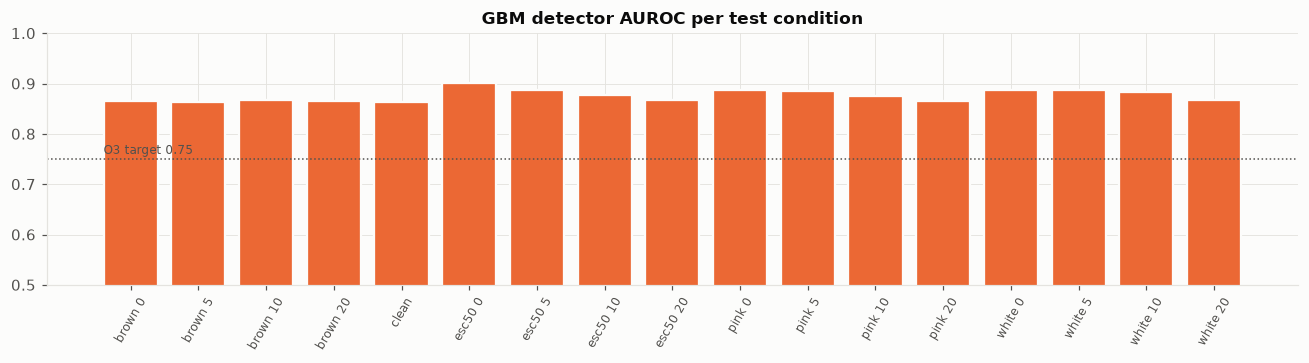

In [10]:
mg = json.load(open(EVAL / MODEL / "metrics.json"))
display(pd.Series({"AUROC, mean frame confidence (greedy)": round(mg["word_auroc_conf_mean"], 3),
                   "AUROC, minimum frame confidence (greedy)": round(mg["word_auroc_conf_min"], 3)}, name="value").to_frame())
det = EVAL / f"{MODEL}_lm4" / "error_detector"
if (det / "metrics.json").exists():
    dm = json.load(open(det / "metrics.json"))
    t = pd.DataFrame({k: v for k, v in dm.items() if isinstance(v, dict) and isinstance(v.get("auroc"), (int, float))}).T
    t = t[["auroc", "ece", "recall_at_30pct", "precision_at_0.5", "recall_at_0.5", "flagged_frac_at_0.5"]].astype(float)
    display(Markdown("**Error detectors on the LM output, all 17 test conditions** (raw = 1 − confidence; isotonic = calibrated confidence; logreg / gbm = trained on dev)"))
    display(t.round(3))
    display(Markdown(f"Selected detector: **{dm.get('selected', 'gbm')}**. O3 targets: AUROC ≥ 0.75, ECE ≤ 0.10, ≥ 70 % of errors in the riskiest 30 % of words (`recall_at_30pct`)."))
    pc = pd.read_csv(det / "per_condition.csv")
    pc["condition"] = (pc.noise_type + " " + pc.snr_db.astype(str).str.replace("nan", "").str.replace("clean", "")).str.strip()
    fig, ax = plt.subplots(figsize=(12, 3.4))
    ax.bar(pc.condition, pc.auroc, color=COLOR[MODEL], edgecolor=SURF, lw=1.5); ax.axhline(.75, color=INK2, ls=":", lw=1)
    ax.text(-.4, .76, "O3 target 0.75", ha="left", fontsize=8, color=INK2)
    ax.set(title="GBM detector AUROC per test condition", ylim=(.5, 1)); ax.tick_params(axis="x", rotation=60, labelsize=8)
    plt.tight_layout(); plt.show()
else:
    print("No trained detector for this model (detectors were trained for B and the M5 models).")

## 9 · Comparison with A_clean
Same table for both models; negative change = this model is better.

In [11]:
def summary_row(name):
    s = load(EVAL / name / "summary.csv", name); p = pool(s)
    r = {"test-clean": split_clean(s, "test.clean"), "test-other": split_clean(s, "test.other"), **head(p)}
    f = EVAL / f"{name}_lm4" / "test_summary.csv"
    if f.exists():
        l = load(f, name); r["test-clean, LM"] = split_clean(l, "test.clean"); r["test-other, LM"] = split_clean(l, "test.other")
        r["esc50 0–5 dB, LM"] = head(pool(l))["esc50 0–5 dB"]
    return r
CMP = pd.DataFrame({PARENT: summary_row(PARENT), MODEL: summary_row(MODEL)})
CMP["change (points)"] = CMP[MODEL] - CMP[PARENT]; CMP["relative %"] = 100 * CMP["change (points)"] / CMP[PARENT]
if (RUNS / PARENT / "eval_log.csv").exists():
    pe = pd.read_csv(RUNS / PARENT / "eval_log.csv"); pb = pe.loc[pe.wer_avg.idxmin()]
    CMP.loc["dev WER mean (best ckpt)"] = [pb.wer_avg * 100, best.wer_avg * 100, (best.wer_avg - pb.wer_avg) * 100, 100 * (best.wer_avg - pb.wer_avg) / pb.wer_avg]
display(CMP.round(2))

,A_clean,B_noisy,change (points),relative %
test-clean,5.85,6.19,0.34,5.82
test-other,13.03,13.08,0.05,0.40
esc50 0–5 dB,38.29,20.12,-18.17,-47.45
brown 0–5 dB,10.26,10.02,-0.24,-2.30
white 0–5 dB,71.53,29.09,-42.44,-59.33
pink 0–5 dB,56.05,23.20,-32.84,-58.60
"all noisy, mean",29.86,16.07,-13.79,-46.17
"test-clean, LM",3.69,3.70,0.01,0.26
"test-other, LM",9.04,8.85,-0.20,-2.18
"esc50 0–5 dB, LM",32.58,15.09,-17.49,-53.68


## 10 · Live transcription example
A 34-second LibriSpeech test-other passage (speaker 3080, CC BY 4.0) shipped with the app in
`deployment/app/examples/`: once clean and once with **white noise at 5 dB SNR**. Greedy decoding on CPU, no LM.
The cell uses the local checkpoint `experiments/runs/B_noisy/best/` when it exists (on the server). On another machine set
`DOWNLOAD = True` to fetch the model from Hugging Face (≈ 380 MB).

In [12]:
DOWNLOAD = False
import soundfile as sf, torch, jiwer
from group9_ds_ai_lab.data.dataset import zscore
from group9_ds_ai_lab.inference.decode import greedy_words
local = RUNS / MODEL / "best"
src = local if (local / "model.safetensors").exists() else (HF_ID if DOWNLOAD else None)
if src is None:
    print(f"Model weights not found locally. Set DOWNLOAD = True to load {HF_ID} from Hugging Face.")
else:
    from transformers import Wav2Vec2ForCTC
    from transformers.utils import logging as hf_logging
    hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error()
    torch.set_num_threads(4)
    model = Wav2Vec2ForCTC.from_pretrained(str(src)).eval()
    exdir = REPO / "deployment" / "app" / "examples"; ref = (exdir / "reference.txt").read_text().strip()
    rows = []
    for name in ["librispeech_clean.flac", "librispeech_white_noise_5dB.flac"]:
        x, sr = sf.read(exdir / name, dtype="float32")
        with torch.no_grad():
            logp = torch.log_softmax(model(torch.from_numpy(zscore(x))[None]).logits[0].float(), -1).numpy()
        hyp, words = greedy_words(logp)
        low = [w["word"] for w in words if w["conf_mean"] < 0.7]
        rows.append({"audio": name.replace("librispeech_", "").replace(".flac", ""), "WER %": round(100 * jiwer.wer(ref, hyp), 2),
                     "words": len(words), "low-confidence words (< 0.7)": " ".join(low[:15]), "transcript (first 200 chars)": hyp[:200]})
    print("REFERENCE (first 200 chars):", ref[:200])
    with pd.option_context("display.max_colwidth", 210): display(pd.DataFrame(rows).set_index("audio"))

REFERENCE (first 200 chars): WOULD IT WOULD LEAVE ME AND THEN I COULD BELIEVE I SHALL NOT ALWAYS HAVE OCCASION FOR IT MY POOR LADY VAVASOUR IS CARRIED TO THE TOWER AND HER GREAT BELLY COULD NOT EXCUSE HER BECAUSE SHE WAS ACQUAINT


,WER %,words,low-confidence words (< 0.7),transcript (first 200 chars)
audio,,,,
clean,3.37,89,,WOULD IT WOULD LEAVE ME AND THEN I COULD BELIEVE I SHALL NOT ALWAYS HAVE OCCASION FOR IT MY POOR LADY VAVISER IS CARRIED TO THE TOWER AND HER GREAT BELLY COULD NOT EXCUSE HER BECAUSE SHE WAS ACQUAINTE
white_noise_5dB,20.22,88,RE TO THE THE BUT WEU A COMMISH,WOULD IT RE MAVE ME AND THEN I COULD BELIEVE I SHALL NOT ALWAYS HAVE OCCASION FOR IT MY POOR LADY VAVISER IS CARRID TO POWER AND THE GREAT BELLY COULD NOT EXCUSE HER BECAUSE SHE WAS ACQUINTED BY SOMEB


## 11 · Summary

In [13]:
gc, go = split_clean(G, "test.clean"), split_clean(G, "test.other")
lc, lo = split_clean(L, "test.clean"), split_clean(L, "test.other")
display(Markdown(f'''
| | {MODEL} |
|---|---|
| Training | {stats["optimizer steps"]:,} steps, {stats["epochs"]} epochs, {stats["GPU hours (1 × L40S)"]} GPU-hours, {stats["non-finite losses"]} non-finite losses |
| Best checkpoint | step {int(best.step):,}: dev WER clean {best.wer_clean*100:.2f} %, noisy {best.wer_noisy*100:.2f} % |
| Test-clean / test-other, greedy | {gc:.2f} / {go:.2f} % |
| Test-clean / test-other, 4-gram LM | **{lc:.2f} / {lo:.2f} %** |
| Held-out ESC-50 at 0–5 dB, greedy / LM | {head(gp)["esc50 0–5 dB"]:.2f} / **{head(lp)["esc50 0–5 dB"]:.2f} %** |
| White noise at 0–5 dB, greedy / LM | {head(gp)["white 0–5 dB"]:.2f} / {head(lp)["white 0–5 dB"]:.2f} % |
| Real-room reverb (held-out rooms), greedy | {E.loc["real-room reverb, no noise", MODEL]:.2f} % |
| Word-error AUROC of raw confidence | {mg["word_auroc_conf_mean"]:.3f} |
'''))


| | B_noisy |
|---|---|
| Training | 36,000 steps, 59 epochs, 3.83 GPU-hours, 0 non-finite losses |
| Best checkpoint | step 34,000: dev WER clean 9.26 %, noisy 17.37 % |
| Test-clean / test-other, greedy | 6.19 / 13.08 % |
| Test-clean / test-other, 4-gram LM | **3.70 / 8.85 %** |
| Held-out ESC-50 at 0–5 dB, greedy / LM | 20.12 / **15.09 %** |
| White noise at 0–5 dB, greedy / LM | 29.09 / 22.79 % |
| Real-room reverb (held-out rooms), greedy | 20.18 % |
| Word-error AUROC of raw confidence | 0.879 |


**Observations**
- **O2 is met.** With the same data, recipe and seed as A, noise training cuts held-out ESC-50 WER at 0–5 dB from 38.3 % to
  20.1 % (greedy), and white noise at 0–5 dB from 71.5 % to 29.1 %.
- The cost on clean speech is small: +0.34 points on test-clean, +0.05 on test-other (greedy); with the LM the two are equal.
- Brown noise (held-out) barely affects either model, because most of its energy is below the speech band.
- Raw-confidence AUROC is a little lower than A's (0.879 vs 0.908): B has removed many of the easy errors.